# CardioIA — Logistic Regression vs. LIF spiking network (ECG)

Classification of PTB ECG heartbeats (187 samples at 125 Hz) as normal or abnormal with three models:

- **A** — logistic regression on the raw signal;
- **B** — 200 leaky integrate-and-fire (LIF) neurons + logistic regression readout on the spike counts;
- **C** — control: same random features as B, without spikes.

Same 80/20 split (seed 42) as the ECG MLP notebook.

## 1. Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, RocCurveDisplay, accuracy_score, balanced_accuracy_score,
                             confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

SEED = 42
CLASS_NAMES = ["normal", "abnormal"]
plt.rcParams["figure.dpi"] = 100

## 2. Data

14552 heartbeats x 187 steps | normal: 4046 | abnormal: 10506
train: 11641 | test: 2911


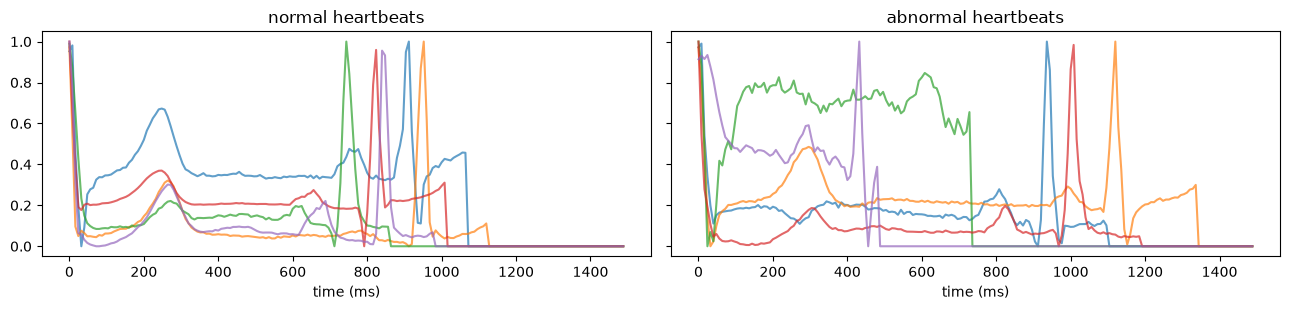

In [2]:
def find_data():
    for folder in [Path("../data/raw/ecg"), Path("data/raw/ecg")]:
        if (folder / "ptbdb_normal.csv").exists():
            return folder
    import kagglehub
    return Path(kagglehub.dataset_download("shayanfazeli/heartbeat"))

DATA_DIR = find_data()
RESULTS_DIR = Path("../results/neuromorphic") if Path("../src").exists() else Path("results/neuromorphic")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

ptb = pd.concat([pd.read_csv(DATA_DIR / "ptbdb_normal.csv", header=None),
                 pd.read_csv(DATA_DIR / "ptbdb_abnormal.csv", header=None)], ignore_index=True)
X = ptb.iloc[:, :-1].to_numpy(np.float32)
y = ptb.iloc[:, -1].to_numpy(int)
print(f"{X.shape[0]} heartbeats x {X.shape[1]} steps | normal: {(y == 0).sum()} | abnormal: {(y == 1).sum()}")

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train: {len(X_train)} | test: {len(X_test)}")

t_ms = np.arange(X.shape[1]) / 125 * 1000
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), sharey=True)
for ax, label in zip(axes, [0, 1]):
    for row in X_train[y_train == label][:5]:
        ax.plot(t_ms, row, alpha=0.7)
    ax.set_title(f"{CLASS_NAMES[label]} heartbeats")
    ax.set_xlabel("time (ms)")
plt.tight_layout()
plt.show()

## 3. Metrics

In [3]:
def evaluate(name, y_true, y_pred, y_score, train_s, infer_s):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_abnormal": precision_score(y_true, y_pred),
        "recall_abnormal": recall_score(y_true, y_pred),
        "recall_normal": recall_score(y_true, y_pred, pos_label=0),
        "f1_abnormal": f1_score(y_true, y_pred),
        "roc_auc": roc_auc_score(y_true, y_score),
        "train_seconds": train_s,
        "inference_ms_per_beat": infer_s / len(y_true) * 1000,
    }

def readout():
    return make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight="balanced"))

results = {}

## 4. Model A — Logistic Regression

In [4]:
t0 = time.perf_counter()
model_a = readout().fit(X_train, y_train)
train_a = time.perf_counter() - t0

t0 = time.perf_counter()
score_a = model_a.predict_proba(X_test)[:, 1]
infer_a = time.perf_counter() - t0
pred_a = (score_a >= 0.5).astype(int)

results["A"] = evaluate("A - Logistic Regression (raw signal)", y_test, pred_a, score_a, train_a, infer_a)
pd.Series(results["A"]).drop("model").round(4)

accuracy                  0.786
balanced_accuracy        0.7849
precision_abnormal       0.9039
recall_abnormal          0.7873
recall_normal            0.7824
f1_abnormal              0.8416
roc_auc                  0.8712
train_seconds            0.1702
inference_ms_per_beat    0.0005
dtype: object

## 5. Model B — LIF network

Each neuron receives $I_i[t] = w^x_i\,x[t] + w^{\Delta}_i\,(x[t]-x[t-1]) + b_i$ (fixed random weights) and follows
$V \leftarrow V + (-V + I)/\tau$. When $V \ge 1$ it spikes, resets to 0 and stays refractory for 2 steps.
Spike counts in 8 time windows are the features of the readout.

Parameters: 200 neurons, τ = 8 steps (64 ms), threshold 1.0, refractory 2 steps.

In [5]:
class LIFEncoder:
    def __init__(self, n_neurons=200, tau=8.0, threshold=1.0, refractory=2, windows=8, seed=SEED):
        rng = np.random.default_rng(seed)
        self.w_signal = rng.normal(0, 2.0, n_neurons).astype(np.float32)
        self.w_slope = rng.normal(0, 8.0, n_neurons).astype(np.float32)
        self.bias = rng.normal(0.3, 0.3, n_neurons).astype(np.float32)
        self.n, self.tau, self.threshold = n_neurons, tau, threshold
        self.refractory, self.windows = refractory, windows

    def current(self, x, dx):
        return x[:, None] * self.w_signal + dx[:, None] * self.w_slope + self.bias

    def run(self, X, record=None):
        # spike counts (beats, neurons * windows) and mean spikes per beat
        B, T = X.shape
        dX = np.diff(X, axis=1, prepend=X[:, :1])
        edges = np.linspace(0, T, self.windows + 1).astype(int)
        v = np.zeros((B, self.n), np.float32)
        ref = np.zeros((B, self.n), np.int8)
        counts = np.zeros((B, self.n, self.windows), np.float32)
        trace_v, trace_s = [], []
        w = 0
        for t in range(T):
            while t >= edges[w + 1]:
                w += 1
            I = self.current(X[:, t], dX[:, t])
            v = np.where(ref == 0, v + (-v + I) / self.tau, v)
            spikes = v >= self.threshold
            v[spikes] = 0.0
            ref = np.where(spikes, self.refractory, np.maximum(ref - 1, 0)).astype(np.int8)
            counts[:, :, w] += spikes
            if record is not None:
                trace_v.append(v[record].copy())
                trace_s.append(spikes[record].copy())
        features = counts.reshape(B, -1)
        if record is not None:
            return features, counts.sum() / B, np.array(trace_v), np.array(trace_s)
        return features, counts.sum() / B

    def rate_features(self, X):
        # model C: ReLU of the same currents, averaged per window
        B, T = X.shape
        dX = np.diff(X, axis=1, prepend=X[:, :1])
        edges = np.linspace(0, T, self.windows + 1).astype(int)
        out = np.zeros((B, self.n, self.windows), np.float32)
        for w in range(self.windows):
            for t in range(edges[w], edges[w + 1]):
                out[:, :, w] += np.maximum(self.current(X[:, t], dX[:, t]), 0)
            out[:, :, w] /= edges[w + 1] - edges[w]
        return out.reshape(B, -1)

lif = LIFEncoder()

### 5.1 Network activity for one abnormal beat

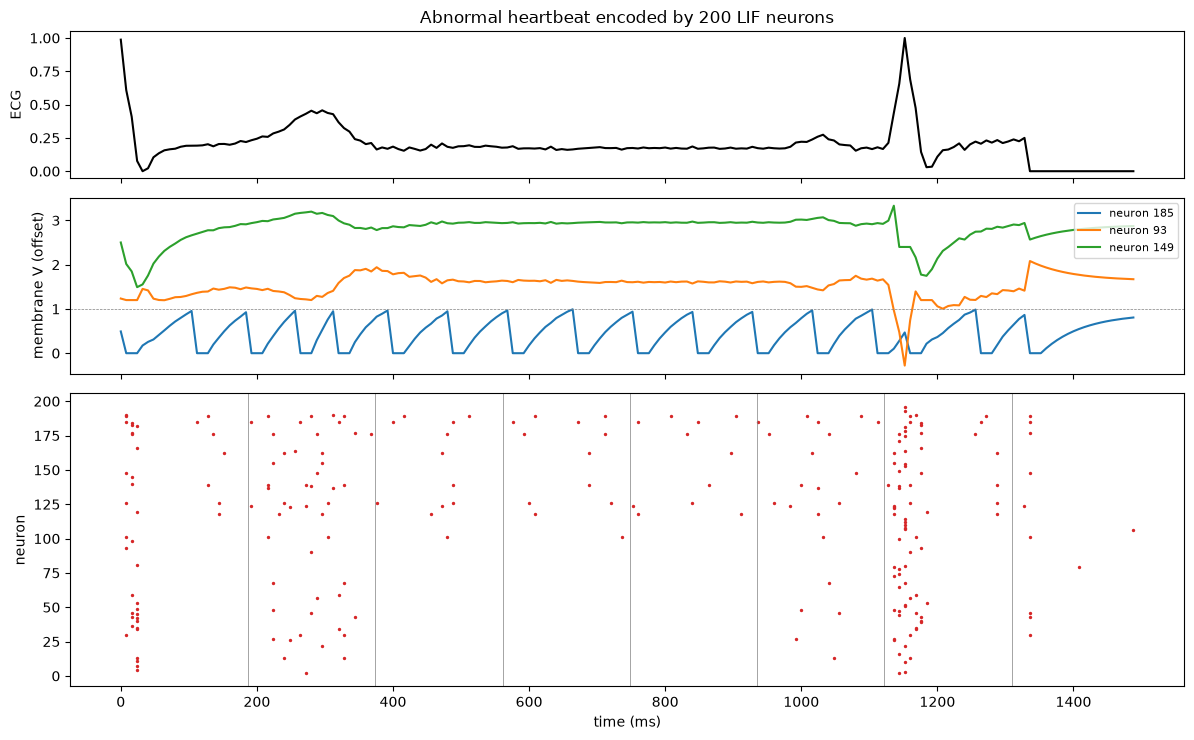

spikes: 234 of 37400 neuron-steps (0.63%)


In [6]:
idx = int(np.where(y_test == 1)[0][0])
_, _, trace_v, trace_s = lif.run(X_test[idx:idx + 1], record=0)
active = np.argsort(trace_s.sum(axis=0))[::-1]
shown = [active[0], active[len(active) // 8], active[len(active) // 4]]

fig, axes = plt.subplots(3, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2, 2]})
axes[0].plot(t_ms, X_test[idx], color="black")
axes[0].set_ylabel("ECG")
axes[0].set_title("Abnormal heartbeat encoded by 200 LIF neurons")
for k, n in enumerate(shown):
    axes[1].plot(t_ms, trace_v[:, n] + k * 1.2, label=f"neuron {n}")
axes[1].axhline(1.0, color="gray", lw=0.5, ls="--")
axes[1].set_ylabel("membrane V (offset)")
axes[1].legend(loc="upper right", fontsize=8)
steps, neurons = np.nonzero(trace_s)
axes[2].scatter(t_ms[steps], neurons, s=2, color="tab:red")
axes[2].set_ylabel("neuron")
axes[2].set_xlabel("time (ms)")
for edge in np.linspace(0, len(t_ms), lif.windows + 1)[1:-1]:
    axes[2].axvline(edge / 125 * 1000, color="gray", lw=0.5)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "lif_dynamics.png", bbox_inches="tight")
plt.show()
print(f"spikes: {int(trace_s.sum())} of {trace_s.size} neuron-steps ({trace_s.mean():.2%})")

### 5.2 Readout training

In [7]:
t0 = time.perf_counter()
F_train, spikes_train = lif.run(X_train)
model_b = readout().fit(F_train, y_train)
train_b = time.perf_counter() - t0

t0 = time.perf_counter()
F_test, spikes_test = lif.run(X_test)
score_b = model_b.predict_proba(F_test)[:, 1]
infer_b = time.perf_counter() - t0
pred_b = (score_b >= 0.5).astype(int)

results["B"] = evaluate("B - LIF spiking network (200 neurons)", y_test, pred_b, score_b, train_b, infer_b)
neuron_steps = lif.n * X.shape[1]
results["B"]["spikes_per_beat"] = float(spikes_test)
results["B"]["activity"] = float(spikes_test / neuron_steps)
print(f"features: {F_train.shape[1]} | spikes per beat: {spikes_test:.0f} ({spikes_test / neuron_steps:.2%})")
pd.Series(results["B"]).drop("model").round(4)

features: 1600 | spikes per beat: 255 (0.68%)


accuracy                   0.8667
balanced_accuracy          0.8678
precision_abnormal         0.9454
recall_abnormal            0.8654
recall_normal              0.8702
f1_abnormal                0.9036
roc_auc                    0.9367
train_seconds              7.3736
inference_ms_per_beat       0.464
spikes_per_beat          255.1017
activity                   0.0068
dtype: object

## 6. Model C — control without spikes

In [8]:
t0 = time.perf_counter()
R_train = lif.rate_features(X_train)
model_c = readout().fit(R_train, y_train)
train_c = time.perf_counter() - t0

t0 = time.perf_counter()
score_c = model_c.predict_proba(lif.rate_features(X_test))[:, 1]
infer_c = time.perf_counter() - t0
pred_c = (score_c >= 0.5).astype(int)

results["C"] = evaluate("C - same random features, no spikes", y_test, pred_c, score_c, train_c, infer_c)
pd.Series(results["C"]).drop("model").round(4)

accuracy                 0.9461
balanced_accuracy        0.9448
precision_abnormal       0.9769
recall_abnormal          0.9477
recall_normal            0.9419
f1_abnormal              0.9621
roc_auc                  0.9844
train_seconds            5.0674
inference_ms_per_beat    0.2375
dtype: object

## 7. Comparison

,accuracy,balanced_accuracy,precision_abnormal,recall_abnormal,recall_normal,f1_abnormal,roc_auc,train_seconds,inference_ms_per_beat
model,,,,,,,,,
A - Logistic Regression (raw signal),0.7860,0.7849,0.9039,0.7873,0.7824,0.8416,0.8712,0.1702,0.0005
B - LIF spiking network (200 neurons),0.8667,0.8678,0.9454,0.8654,0.8702,0.9036,0.9367,7.3736,0.4640
"C - same random features, no spikes",0.9461,0.9448,0.9769,0.9477,0.9419,0.9621,0.9844,5.0674,0.2375


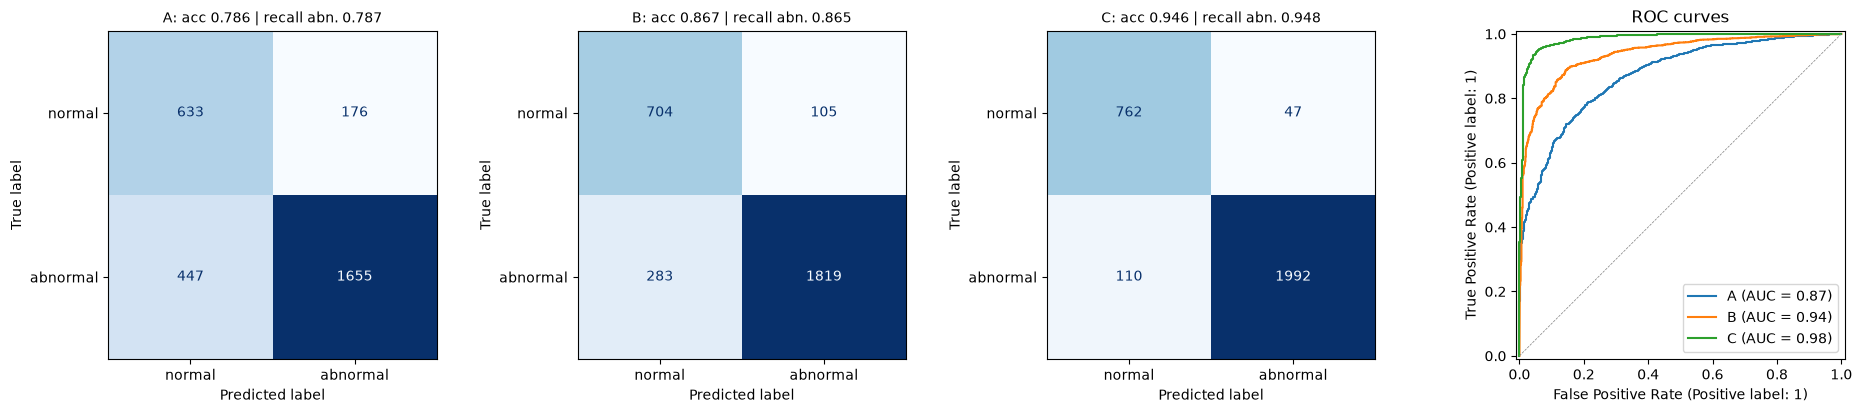

In [9]:
table = pd.DataFrame(results.values()).set_index("model")
display(table.drop(columns=["spikes_per_beat", "activity"], errors="ignore").round(4))

fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
for ax, (key, pred) in zip(axes[:3], [("A", pred_a), ("B", pred_b), ("C", pred_c)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASS_NAMES).plot(
        ax=ax, colorbar=False, cmap="Blues", values_format="d")
    ax.set_title(f"{key}: acc {results[key]['accuracy']:.3f} | recall abn. {results[key]['recall_abnormal']:.3f}",
                 fontsize=10)
for key, score in [("A", score_a), ("B", score_b), ("C", score_c)]:
    RocCurveDisplay.from_predictions(y_test, score, name=key, ax=axes[3])
axes[3].plot([0, 1], [0, 1], color="gray", lw=0.5, ls="--")
axes[3].set_title("ROC curves")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "comparison_confusion_roc.png", bbox_inches="tight")
plt.show()

## 8. Number of neurons

,neurons,accuracy,balanced_accuracy,recall_abnormal,spikes_per_beat,seconds
0,25,0.7661,0.7654,0.7669,17.778099,0.9269
1,50,0.8052,0.8119,0.7969,68.006500,1.6873
2,100,0.8406,0.8543,0.8235,119.626602,4.0338
3,200,0.8667,0.8678,0.8654,255.101700,8.9026
4,400,0.8894,0.8827,0.8977,582.026794,18.2635


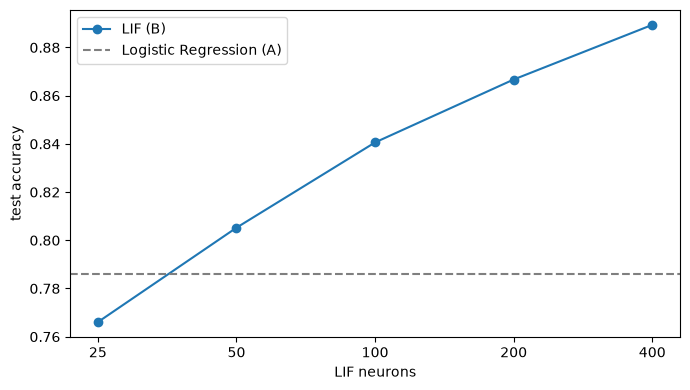

In [10]:
sweep = []
for n in [25, 50, 100, 200, 400]:
    enc = LIFEncoder(n_neurons=n)
    t0 = time.perf_counter()
    Ftr, _ = enc.run(X_train)
    Fte, spk = enc.run(X_test)
    clf = readout().fit(Ftr, y_train)
    pred = clf.predict(Fte)
    sweep.append({"neurons": n, "accuracy": accuracy_score(y_test, pred),
                  "balanced_accuracy": balanced_accuracy_score(y_test, pred),
                  "recall_abnormal": recall_score(y_test, pred), "spikes_per_beat": spk,
                  "seconds": time.perf_counter() - t0})
sweep = pd.DataFrame(sweep)
display(sweep.round(4))

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["neurons"], sweep["accuracy"], "o-", label="LIF (B)")
ax.axhline(results["A"]["accuracy"], color="tab:gray", ls="--", label="Logistic Regression (A)")
ax.set_xscale("log", base=2)
ax.set_xticks(sweep["neurons"], sweep["neurons"])
ax.set_xlabel("LIF neurons")
ax.set_ylabel("test accuracy")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS_DIR / "neurons_sweep.png", bbox_inches="tight")
plt.show()

## 9. Robustness to noise

Gaussian noise added to the test signals only.

,A - LogReg,B - LIF,C - no spikes
sigma,,,
0.00,0.7860,0.8667,0.9461
0.02,0.7643,0.8485,0.7939
0.05,0.6901,0.7791,0.6870
0.10,0.6441,0.6929,0.5565
0.20,0.6025,0.7056,0.4112


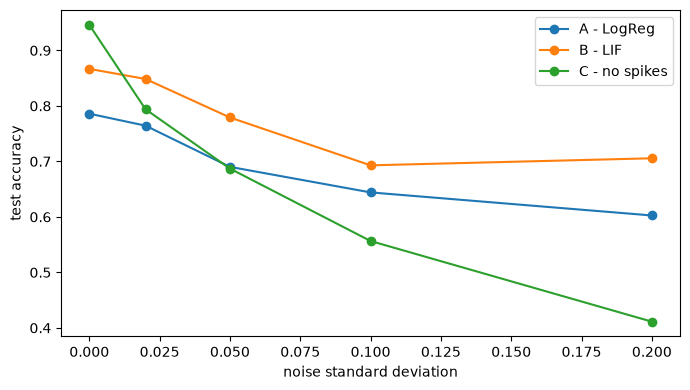

In [11]:
rng = np.random.default_rng(SEED)
noise_rows = []
for sigma in [0.0, 0.02, 0.05, 0.1, 0.2]:
    Xn = np.clip(X_test + rng.normal(0, sigma, X_test.shape).astype(np.float32), 0, 1)
    noise_rows.append({
        "sigma": sigma,
        "A - LogReg": accuracy_score(y_test, model_a.predict(Xn)),
        "B - LIF": accuracy_score(y_test, model_b.predict(lif.run(Xn)[0])),
        "C - no spikes": accuracy_score(y_test, model_c.predict(lif.rate_features(Xn))),
    })
noise = pd.DataFrame(noise_rows).set_index("sigma")
display(noise.round(4))

ax = noise.plot(marker="o", figsize=(7, 4))
ax.set_xlabel("noise standard deviation")
ax.set_ylabel("test accuracy")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "noise_robustness.png", bbox_inches="tight")
plt.show()

## 10. Cost per heartbeat

In [12]:
T = X.shape[1]
cost = pd.DataFrame([
    {"model": "A - Logistic Regression", "dense operations per beat": T,
     "spikes per beat": None, "inference ms/beat": results["A"]["inference_ms_per_beat"]},
    {"model": "B - LIF (200 neurons)", "dense operations per beat": lif.n * T * 3 + F_train.shape[1],
     "spikes per beat": round(results["B"]["spikes_per_beat"]),
     "inference ms/beat": results["B"]["inference_ms_per_beat"]},
])
display(cost.round(4))

,model,dense operations per beat,spikes per beat,inference ms/beat
0,A - Logistic Regression,187,NaN,0.0005
1,B - LIF (200 neurons),113800,255.0,0.4640


## 11. Conclusions

- B beats A on every metric (accuracy 0.867 vs 0.786, ROC-AUC 0.937 vs 0.871) and improves with more neurons.
- On clean data the control C is the best model (0.946), so most of the gain over A comes from the random
  nonlinear features, not from the spikes.
- With noise, B is the most robust model at every level tested (0.706 at σ = 0.2, against 0.603 for A and
  0.411 for C).
- On a CPU, B is much slower than A. On event-driven neuromorphic hardware its cost would depend on the
  ~255 spikes per beat (under 1% of neuron-steps).
- Limitations: untrained spiking layer, single seed, beats split randomly instead of by patient. The ECG MLP
  (0.9615 accuracy) is still the best model on clean data.

In [14]:
summary = {
    "dataset": "PTB Diagnostic ECG (Kaggle heartbeat), 80/20 stratified split, seed 42",
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "models": {k: {m: (float(v) if not isinstance(v, str) else v) for m, v in r.items()} for k, r in results.items()},
    "neurons_sweep": sweep.round(4).to_dict(orient="records"),
    "noise_robustness": noise.round(4).reset_index().to_dict(orient="records"),
    "lif_parameters": {"neurons": lif.n, "tau_steps": lif.tau, "threshold": lif.threshold,
                       "refractory_steps": lif.refractory, "windows": lif.windows},
}
(RESULTS_DIR / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")

3379